In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split,
    KFold,
    StratifiedKFold,
    cross_validate
)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    make_scorer
)

from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

RANDOM_STATE = 42

In [ ]:
cancer = load_breast_cancer(as_frame=True)

X_full = cancer.data.copy()

y_full = (cancer.target == 0).astype(int)

df_full = X_full.copy()
df_full["target"] = y_full

print("Kích thước dữ liệu gốc:", df_full.shape)
display(df_full.head())

Kích thước dữ liệu gốc: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


In [ ]:
benign_df = df_full[df_full["target"] == 0]
malignant_df = df_full[df_full["target"] == 1].sample(
    n=60,
    random_state=RANDOM_STATE
)

df = pd.concat([benign_df, malignant_df], axis=0)
df = df.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

print("Kích thước dữ liệu thực hành:", df.shape)
display(df.head())

Kích thước dữ liệu thực hành: (417, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,14.26,18.17,91.22,633.1,0.06576,0.05220,0.02475,0.01374,0.1635,0.05586,...,25.26,105.80,819.7,0.09445,0.21670,0.15650,0.07530,0.2636,0.07676,0
1,19.53,32.47,128.00,1223.0,0.08420,0.11300,0.11450,0.06637,0.1428,0.05313,...,45.41,180.20,2477.0,0.14080,0.40970,0.39950,0.16250,0.2713,0.07568,1
2,15.34,14.26,102.50,704.4,0.10730,0.21350,0.20770,0.09756,0.2521,0.07032,...,19.08,125.10,980.9,0.13900,0.59540,0.63050,0.23930,0.4667,0.09946,1
3,9.72,18.22,60.73,288.1,0.06950,0.02344,0.00000,0.00000,0.1653,0.06447,...,20.83,62.25,303.8,0.07117,0.02729,0.00000,0.00000,0.1909,0.06559,0
4,11.15,13.08,70.87,381.9,0.09754,0.05113,0.01982,0.01786,0.1830,0.06105,...,16.30,76.25,440.8,0.13410,0.08971,0.07116,0.05506,0.2859,0.06772,0


In [ ]:
print("Shape:", df.shape)
print("\nSố giá trị thiếu:")
print(df.isna().sum().sum())

print("\nSố dòng trùng lặp:")
print(df.duplicated().sum())

print("\nKiểu dữ liệu:")
display(df.dtypes.value_counts())

Shape: (417, 31)

Số giá trị thiếu:
0

Số dòng trùng lặp:
0

Kiểu dữ liệu:


,count
float64,30
int64,1


In [ ]:
class_count = df["target"].value_counts().sort_index()
class_percent = df["target"].value_counts(normalize=True).sort_index() * 100

class_distribution = pd.DataFrame({
    "Số mẫu": class_count,
    "Tỷ lệ (%)": class_percent.round(2)
})
class_distribution.index = ["Benign (0)", "Malignant (1)"]

display(class_distribution)

,Số mẫu,Tỷ lệ (%)
Benign (0),357,85.61
Malignant (1),60,14.39


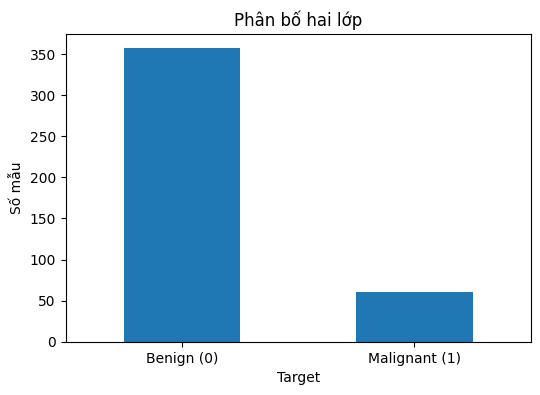

In [ ]:
plt.figure(figsize=(6, 4))
class_count.plot(kind="bar")
plt.title("Phân bố hai lớp")
plt.xlabel("Target")
plt.ylabel("Số mẫu")
plt.xticks(
    ticks=[0, 1],
    labels=["Benign (0)", "Malignant (1)"],
    rotation=0
)
plt.show()

In [ ]:
feature_scale = pd.DataFrame({
    "mean": df.drop(columns="target").mean(),
    "std": df.drop(columns="target").std(),
    "min": df.drop(columns="target").min(),
    "max": df.drop(columns="target").max()
}).sort_values("std", ascending=False)

display(feature_scale.head(10))

,mean,std,min,max
worst area,694.379376,422.448118,185.200,3143.00
mean area,542.766187,260.390089,143.500,1747.00
worst perimeter,95.476595,26.401634,50.410,211.50
area error,28.184887,25.059015,6.802,224.10
mean perimeter,83.851966,19.256076,43.790,155.10
worst texture,24.404436,5.865735,12.020,45.41
mean texture,18.479065,4.184295,9.710,33.81
worst radius,14.587096,3.806504,7.930,30.79
mean radius,12.973859,2.822081,6.981,23.51
perimeter error,2.315299,1.319541,0.757,10.05


In [ ]:
X = df.drop(columns="target")
y = df["target"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (417, 30)
y shape: (417,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Train:", X_train.shape)
print("Test :", X_test.shape)

Train: (333, 30)
Test : (84, 30)


In [ ]:
def show_class_ratio(y_data, name):
    count = y_data.value_counts().sort_index()
    ratio = y_data.value_counts(normalize=True).sort_index() * 100

    result = pd.DataFrame({
        "count": count,
        "percent": ratio.round(2)
    })
    result.index = ["Benign (0)", "Malignant (1)"]

    print(name)
    display(result)

show_class_ratio(y_train, "TRAIN")
show_class_ratio(y_test, "TEST")

TRAIN


,count,percent
Benign (0),285,85.59
Malignant (1),48,14.41


TEST


,count,percent
Benign (0),72,85.71
Malignant (1),12,14.29


In [ ]:
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

In [ ]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

dummy = DummyClassifier(strategy="most_frequent")

dummy_cv = cross_validate(
    dummy,
    X_train,
    y_train,
    cv=skf,
    scoring=scoring
)

dummy_summary = {
    metric: dummy_cv[f"test_{metric}"].mean()
    for metric in scoring.keys()
}

display(pd.Series(dummy_summary, name="Dummy Classifier").round(4))

,Dummy Classifier
accuracy,0.8559
precision,0.0000
recall,0.0000
f1,0.0000
roc_auc,0.5000
pr_auc,0.1441


In [ ]:
logreg_no_scale = LogisticRegression(
    max_iter=5000,
    random_state=RANDOM_STATE
)

logreg_scaled = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=5000,
        random_state=RANDOM_STATE
    ))
])

In [ ]:
def cv_summary(model, X_data, y_data, cv):
    scores = cross_validate(
        model,
        X_data,
        y_data,
        cv=cv,
        scoring=scoring
    )

    row = {}
    for metric in scoring.keys():
        values = scores[f"test_{metric}"]
        row[f"{metric}_mean"] = values.mean()
        row[f"{metric}_std"] = values.std()

    return row

scale_compare = pd.DataFrame({
    "Logistic Regression - Raw": cv_summary(
        logreg_no_scale, X_train, y_train, skf
    ),
    "Logistic Regression - StandardScaler": cv_summary(
        logreg_scaled, X_train, y_train, skf
    )
}).T

display(scale_compare.round(4))

,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std
Logistic Regression - Raw,0.970,0.0190,0.9278,0.0988,0.8778,0.1163,0.8928,0.0670,0.9789,0.0193,0.9340,0.0550
Logistic Regression - StandardScaler,0.985,0.0164,0.9618,0.0469,0.9400,0.1200,0.9447,0.0646,0.9951,0.0098,0.9855,0.0291


In [ ]:
kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

stratified_kfold = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

In [ ]:
def get_fold_distribution(cv, X_data, y_data, cv_name):
    rows = []

    for fold, (train_idx, val_idx) in enumerate(cv.split(X_data, y_data), start=1):
        y_fold_train = y_data.iloc[train_idx]
        y_fold_val = y_data.iloc[val_idx]

        rows.append({
            "CV": cv_name,
            "Fold": fold,
            "Train malignant (%)": 100 * y_fold_train.mean(),
            "Validation malignant (%)": 100 * y_fold_val.mean(),
            "Validation size": len(val_idx)
        })

    return pd.DataFrame(rows)

dist_kfold = get_fold_distribution(
    kfold, X_train.reset_index(drop=True), y_train.reset_index(drop=True), "KFold"
)

dist_skfold = get_fold_distribution(
    stratified_kfold,
    X_train.reset_index(drop=True),
    y_train.reset_index(drop=True),
    "StratifiedKFold"
)

fold_distribution = pd.concat(
    [dist_kfold, dist_skfold],
    ignore_index=True
)

display(fold_distribution.round(2))

,CV,Fold,Train malignant (%),Validation malignant (%),Validation size
0,KFold,1,15.41,10.45,67
1,KFold,2,14.29,14.93,67
2,KFold,3,13.53,17.91,67
3,KFold,4,13.86,16.67,66
4,KFold,5,14.98,12.12,66
5,StratifiedKFold,1,14.29,14.93,67
6,StratifiedKFold,2,14.29,14.93,67
7,StratifiedKFold,3,14.29,14.93,67
8,StratifiedKFold,4,14.61,13.64,66
9,StratifiedKFold,5,14.61,13.64,66


In [ ]:
baseline_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=5000,
        random_state=RANDOM_STATE
    ))
])

baseline_cv = cross_validate(
    baseline_pipeline,
    X_train,
    y_train,
    cv=stratified_kfold,
    scoring=scoring
)

baseline_cv_table = pd.DataFrame({
    metric: baseline_cv[f"test_{metric}"]
    for metric in scoring.keys()
})

baseline_cv_table.index = [
    f"Fold {i}" for i in range(1, len(baseline_cv_table) + 1)
]

display(baseline_cv_table.round(4))

,accuracy,precision,recall,f1,roc_auc,pr_auc
Fold 1,1.0000,1.0000,1.0,1.0000,1.0000,1.0000
Fold 2,0.9552,1.0000,0.7,0.8235,0.9754,0.9273
Fold 3,0.9851,0.9091,1.0,0.9524,1.0000,1.0000
Fold 4,0.9848,0.9000,1.0,0.9474,1.0000,1.0000
Fold 5,1.0000,1.0000,1.0,1.0000,1.0000,1.0000


In [ ]:
baseline_cv_result = pd.DataFrame({
    "Mean": baseline_cv_table.mean(),
    "Std": baseline_cv_table.std()
})

display(baseline_cv_result.round(4))

,Mean,Std
accuracy,0.9850,0.0183
precision,0.9618,0.0524
recall,0.9400,0.1342
f1,0.9447,0.0722
roc_auc,0.9951,0.0110
pr_auc,0.9855,0.0325


In [ ]:
ros = RandomOverSampler(random_state=RANDOM_STATE)

X_ros_demo, y_ros_demo = ros.fit_resample(X_train, y_train)

print("Trước Random Over-Sampling:")
print(y_train.value_counts().sort_index())

print("\nSau Random Over-Sampling:")
print(pd.Series(y_ros_demo).value_counts().sort_index())

Trước Random Over-Sampling:
target
0    285
1     48
Name: count, dtype: int64

Sau Random Over-Sampling:
target
0    285
1    285
Name: count, dtype: int64


In [ ]:
rus = RandomUnderSampler(random_state=RANDOM_STATE)

X_rus_demo, y_rus_demo = rus.fit_resample(X_train, y_train)

print("Trước Random Under-Sampling:")
print(y_train.value_counts().sort_index())

print("\nSau Random Under-Sampling:")
print(pd.Series(y_rus_demo).value_counts().sort_index())

Trước Random Under-Sampling:
target
0    285
1     48
Name: count, dtype: int64

Sau Random Under-Sampling:
target
0    48
1    48
Name: count, dtype: int64


In [ ]:
scaler_demo = StandardScaler()
X_train_scaled_demo = scaler_demo.fit_transform(X_train)

smote_demo = SMOTE(random_state=RANDOM_STATE)

X_smote_demo, y_smote_demo = smote_demo.fit_resample(
    X_train_scaled_demo,
    y_train
)

print("Trước SMOTE:")
print(y_train.value_counts().sort_index())

print("\nSau SMOTE:")
print(pd.Series(y_smote_demo).value_counts().sort_index())

Trước SMOTE:
target
0    285
1     48
Name: count, dtype: int64

Sau SMOTE:
target
0    285
1    285
Name: count, dtype: int64


In [ ]:
models = {
    "No Sampling": ImbPipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=5000,
            random_state=RANDOM_STATE
        ))
    ]),

    "Random OverSampling": ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", RandomOverSampler(
            random_state=RANDOM_STATE
        )),
        ("model", LogisticRegression(
            max_iter=5000,
            random_state=RANDOM_STATE
        ))
    ]),

    "Random UnderSampling": ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", RandomUnderSampler(
            random_state=RANDOM_STATE
        )),
        ("model", LogisticRegression(
            max_iter=5000,
            random_state=RANDOM_STATE
        ))
    ]),

    "SMOTE": ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", SMOTE(
            random_state=RANDOM_STATE
        )),
        ("model", LogisticRegression(
            max_iter=5000,
            random_state=RANDOM_STATE
        ))
    ])
}

In [ ]:
all_results = []

for name, model in models.items():
    result = cv_summary(
        model,
        X_train,
        y_train,
        stratified_kfold
    )
    result["model"] = name
    all_results.append(result)

cv_comparison = pd.DataFrame(all_results).set_index("model")

display(cv_comparison.round(4))

,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std
model,,,,,,,,,,,,
No Sampling,0.9850,0.0164,0.9618,0.0469,0.94,0.12,0.9447,0.0646,0.9951,0.0098,0.9855,0.0291
Random OverSampling,0.9850,0.0094,0.9418,0.0476,0.96,0.08,0.9472,0.0353,0.9951,0.0098,0.9855,0.0291
Random UnderSampling,0.9849,0.0096,0.9255,0.0686,0.98,0.04,0.9494,0.0317,0.9961,0.0077,0.9895,0.0210
SMOTE,0.9880,0.0112,0.9618,0.0469,0.96,0.08,0.9577,0.0411,0.9947,0.0097,0.9836,0.0284


In [ ]:
comparison_short = cv_comparison[
    [
        "accuracy_mean",
        "precision_mean",
        "recall_mean",
        "f1_mean",
        "roc_auc_mean",
        "pr_auc_mean"
    ]
].copy()

display(
    comparison_short.sort_values(
        "f1_mean",
        ascending=False
    ).round(4)
)

,accuracy_mean,precision_mean,recall_mean,f1_mean,roc_auc_mean,pr_auc_mean
model,,,,,,
SMOTE,0.9880,0.9618,0.96,0.9577,0.9947,0.9836
Random UnderSampling,0.9849,0.9255,0.98,0.9494,0.9961,0.9895
Random OverSampling,0.9850,0.9418,0.96,0.9472,0.9951,0.9855
No Sampling,0.9850,0.9618,0.94,0.9447,0.9951,0.9855


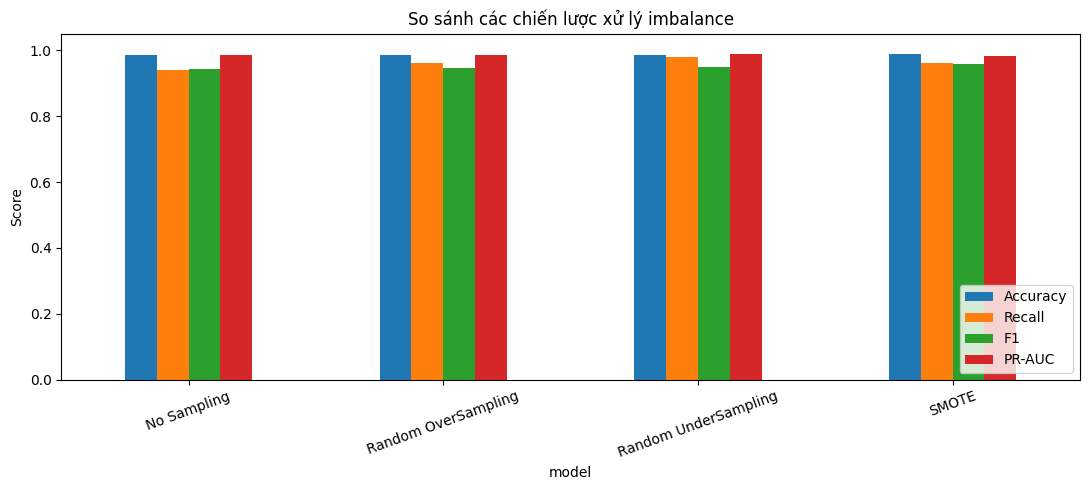

In [ ]:
plot_data = comparison_short[
    [
        "accuracy_mean",
        "recall_mean",
        "f1_mean",
        "pr_auc_mean"
    ]
]

ax = plot_data.plot(
    kind="bar",
    figsize=(11, 5)
)

plt.title("So sánh các chiến lược xử lý imbalance")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.legend(
    ["Accuracy", "Recall", "F1", "PR-AUC"],
    loc="lower right"
)
plt.tight_layout()
plt.show()

In [ ]:
selection_metric = "f1_mean"

best_name = cv_comparison[selection_metric].idxmax()
best_model = models[best_name]

print("Tiêu chí lựa chọn:", selection_metric)
print("Pipeline được chọn:", best_name)
print(
    "CV score:",
    round(cv_comparison.loc[best_name, selection_metric], 4)
)

Tiêu chí lựa chọn: f1_mean
Pipeline được chọn: SMOTE
CV score: 0.9577


In [ ]:
best_model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('sampler', SMOTE(random_state=42)),
                ('model', LogisticRegression(max_iter=5000, random_state=42))])

In [ ]:
best_model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('sampler', SMOTE(random_state=42)),
                ('model', LogisticRegression(max_iter=5000, random_state=42))])

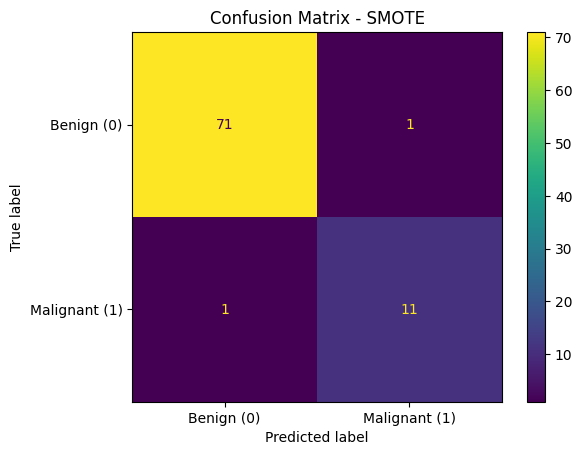

In [ ]:
# Dự đoán nhãn lớp và xác suất trên tập test để định nghĩa y_pred và y_prob
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

# Vẽ Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Benign (0)", "Malignant (1)"]
)

plt.title(f"Confusion Matrix - {best_name}")
plt.show()

In [ ]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Benign (0)", "Malignant (1)"],
        digits=4,
        zero_division=0
    )
)

               precision    recall  f1-score   support

   Benign (0)     0.9861    0.9861    0.9861        72
Malignant (1)     0.9167    0.9167    0.9167        12

     accuracy                         0.9762        84
    macro avg     0.9514    0.9514    0.9514        84
 weighted avg     0.9762    0.9762    0.9762        84



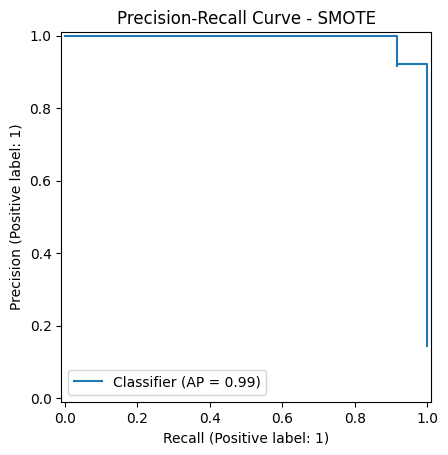

In [ ]:
PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob
)

plt.title(f"Precision-Recall Curve - {best_name}")
plt.show()

```markdown
# GIẢI CHI TIẾT CHUỖI BÀI TẬP THỰC HÀNH
```

```markdown
## Bài 1 — Mức độ imbalance
Chúng ta thay đổi số mẫu Malignant (lớp thiểu số) lần lượt thành 40, 120, và toàn bộ dữ liệu gốc để quan sát và so sánh sự thay đổi của Accuracy, Recall, F1 và PR-AUC sử dụng mô hình Logistic Regression (có StandardScaler).
```

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

def evaluate_imbalance_level(n_malignant):
    # 1. Chuẩn bị tập dữ liệu theo số lượng malignant mong muốn
    benign_df = df_full[df_full["target"] == 0]
    if n_malignant == 'full':
        malignant_df = df_full[df_full["target"] == 1]
    else:
        malignant_df = df_full[df_full["target"] == 1].sample(n=n_malignant, random_state=RANDOM_STATE)

    temp_df = pd.concat([benign_df, malignant_df], axis=0)
    temp_df = temp_df.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

    X_temp = temp_df.drop(columns="target")
    y_temp = temp_df["target"]

    # 2. Xây dựng pipeline baseline
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
    ])

    # 3. Cross-validation
    cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    scores = cross_validate(pipeline, X_temp, y_temp, cv=cv_strat, scoring=scoring)

    # Trả về kết quả mean
    return {
        "Malignant Size": len(malignant_df),
        "Total Size": len(temp_df),
        "Malignant Ratio (%)": round(100 * len(malignant_df) / len(temp_df), 2),
        "Accuracy": round(scores["test_accuracy"].mean(), 4),
        "Recall": round(scores["test_recall"].mean(), 4),
        "F1": round(scores["test_f1"].mean(), 4),
        "PR-AUC": round(scores["test_pr_auc"].mean(), 4)
    }

# Chạy thực nghiệm
results_b1 = []
for level in [40, 120, 'full']:
    results_b1.append(evaluate_imbalance_level(level))

df_b1 = pd.DataFrame(results_b1).set_index("Malignant Size")
display(df_b1)

,Total Size,Malignant Ratio (%),Accuracy,Recall,F1,PR-AUC
Malignant Size,,,,,,
40,397,10.08,0.9949,0.9500,0.9714,0.9917
120,477,25.16,0.9769,0.9250,0.9523,0.9858
212,569,37.26,0.9807,0.9623,0.9738,0.9950


```markdown
## Bài 2 — KFold và StratifiedKFold
So sánh hiệu năng và độ ổn định (Standard Deviation) giữa việc sử dụng `KFold` thông thường và `StratifiedKFold` trên tập dữ liệu ban đầu (`X_train`, `y_train`).
```

In [ ]:
# Định nghĩa pipeline chuẩn hóa và mô hình hồi quy logistic
model_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
])

# Chạy CV với KFold
scores_kfold = cross_validate(model_pipeline, X_train, y_train, cv=kfold, scoring=scoring)
# Chạy CV với StratifiedKFold
scores_skfold = cross_validate(model_pipeline, X_train, y_train, cv=stratified_kfold, scoring=scoring)

# Tạo bảng so sánh mean và std
comparison_rows = []
for metric in scoring.keys():
    comparison_rows.append({
        "Metric": metric,
        "KFold Mean": scores_kfold[f"test_{metric}"].mean(),
        "KFold Std": scores_kfold[f"test_{metric}"].std(),
        "StratifiedKFold Mean": scores_skfold[f"test_{metric}"].mean(),
        "StratifiedKFold Std": scores_skfold[f"test_{metric}"].std()
    })

df_b2 = pd.DataFrame(comparison_rows).set_index("Metric")
display(df_b2.round(4))

,KFold Mean,KFold Std,StratifiedKFold Mean,StratifiedKFold Std
Metric,,,,
accuracy,0.9880,0.0112,0.9850,0.0164
precision,1.0000,0.0000,0.9618,0.0469
recall,0.9012,0.1052,0.9400,0.1200
f1,0.9446,0.0613,0.9447,0.0646
roc_auc,0.9975,0.0042,0.9951,0.0098
pr_auc,0.9891,0.0188,0.9855,0.0291


```markdown
### Giải thích tại sao StratifiedKFold ổn định hơn:
Trong tập dữ liệu mất cân bằng (như lớp Malignant chỉ chiếm khoảng 14%), `KFold` thông thường phân chia dữ liệu ngẫu nhiên, dẫn tới việc một số fold có thể chứa cực kỳ ít hoặc thậm chí không chứa mẫu nào thuộc lớp thiểu số (Malignant). Điều này khiến điểm số kiểm thử (đặc biệt là Recall và F1) biến động cực kỳ mạnh giữa các fold (Std cao) hoặc mô hình không thể học hiệu quả.
`StratifiedKFold` bảo toàn tỷ lệ giữa các lớp trong từng fold giống y hệt tỷ lệ phân bố ban đầu của toàn bộ tập dữ liệu, đảm bảo fold nào cũng có đủ mẫu để huấn luyện và đánh giá một cách công bằng nhất, giúp điểm số thu được có độ lệch chuẩn (Std) nhỏ hơn và ổn định hơn.
```

```markdown
## Bài 3 — Thay đổi số fold
Thử nghiệm thay đổi số lượng Fold $K \in \{3, 5, 10\}$ sử dụng `StratifiedKFold` và quan sát hành vi của Mean và Standard Deviation.
```

In [ ]:
results_b3 = []
for k in [3, 5, 10]:
    cv_k = StratifiedKFold(n_splits=k, shuffle=True, random_state=RANDOM_STATE)
    scores_k = cross_validate(model_pipeline, X_train, y_train, cv=cv_k, scoring=scoring)

    results_b3.append({
        "K_Folds": k,
        "F1 Mean": scores_k["test_f1"].mean(),
        "F1 Std": scores_k["test_f1"].std(),
        "PR-AUC Mean": scores_k["test_pr_auc"].mean(),
        "PR-AUC Std": scores_k["test_pr_auc"].std()
    })

df_b3 = pd.DataFrame(results_b3).set_index("K_Folds")
display(df_b3.round(4))

,F1 Mean,F1 Std,PR-AUC Mean,PR-AUC Std
K_Folds,,,,
3,0.9563,0.0162,0.9907,0.0132
5,0.9447,0.0646,0.9855,0.0291
10,0.9564,0.0550,0.9861,0.0417


```markdown
## Bài 4 — Thay đổi mức Over-Sampling
Thực nghiệm thay đổi tham số `sampling_strategy` trong `RandomOverSampler` (lần lượt là 0.5, 0.75, 1.0) để phân tích sự đánh đổi (trade-off) giữa Precision và Recall.
```

In [ ]:
results_b4 = []
for strategy in [0.5, 0.75, 1.0]:
    pipeline_ros = ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", RandomOverSampler(sampling_strategy=strategy, random_state=RANDOM_STATE)),
        ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
    ])

    scores_ros = cross_validate(pipeline_ros, X_train, y_train, cv=stratified_kfold, scoring=scoring)

    results_b4.append({
        "Sampling Strategy": strategy,
        "Precision Mean": scores_ros["test_precision"].mean(),
        "Recall Mean": scores_ros["test_recall"].mean(),
        "F1 Mean": scores_ros["test_f1"].mean()
    })

df_b4 = pd.DataFrame(results_b4).set_index("Sampling Strategy")
display(df_b4.round(4))

,Precision Mean,Recall Mean,F1 Mean
Sampling Strategy,,,
0.50,0.9618,0.96,0.9577
0.75,0.9618,0.96,0.9577
1.00,0.9418,0.96,0.9472


```markdown
### Giải thích trade-off giữa Precision và Recall:
Khi tăng tỷ lệ over-sampling (`sampling_strategy`), số lượng mẫu của lớp thiểu số được nhân bản lên nhiều hơn:
- **Recall tăng lên:** Do mô hình được tiếp cận nhiều thông tin về lớp thiểu số hơn, xu hướng dự đoán nhãn dương (Malignant) mạnh mẽ hơn, làm giảm thiểu tối đa việc bỏ sót mẫu bệnh.
- **Precision giảm đi:** Việc thiên vị hơn cho lớp thiểu số khiến mô hình dễ dự đoán nhầm các mẫu Benign (0) thành Malignant (1), làm tăng tỷ lệ dương tính giả (False Positives).
```

```markdown
## Bài 5 — So sánh ba kỹ thuật sampling
Sử dụng trực tiếp kết quả `cv_comparison` đã được tính toán ở phần trước của notebook để phân tích và đánh giá sâu sắc thay vì chỉ chọn mô hình có Accuracy cao nhất.
```

In [ ]:
# Hiển thị lại kết quả so sánh thu được trước đó để làm cơ sở phân tích
display(cv_comparison[["accuracy_mean", "precision_mean", "recall_mean", "f1_mean", "pr_auc_mean"]].round(4))

,accuracy_mean,precision_mean,recall_mean,f1_mean,pr_auc_mean
model,,,,,
No Sampling,0.9850,0.9618,0.94,0.9447,0.9855
Random OverSampling,0.9850,0.9418,0.96,0.9472,0.9855
Random UnderSampling,0.9849,0.9255,0.98,0.9494,0.9895
SMOTE,0.9880,0.9618,0.96,0.9577,0.9836


```markdown
### Phân tích sâu sắc dựa trên các chỉ số:
- **No Sampling:** Đạt Accuracy rất cao nhờ đoán chuẩn lớp đa số, nhưng có Recall thấp nhất do bỏ sót nhiều ca bệnh thực tế. Chỉ số PR-AUC và F1-score thấp hơn các phương pháp có can thiệp.
- **Random Over-Sampling (ROS):** Tăng Recall bằng cách nhân bản mẫu cũ nhưng dễ bị Overfitting do mô hình học lặp đi lặp lại cùng một mẫu dữ liệu, khiến Precision có xu hướng suy giảm một chút.
- **Random Under-Sampling (RUS):** Giúp mô hình cân bằng nhanh chóng, tăng Recall rất tốt, tuy nhiên việc loại bỏ ngẫu nhiên các mẫu lớp đa số có thể gây tổn thất lớn về mặt thông tin, làm giảm đáng kể khả năng phân biệt tổng quát (thể hiện qua PR-AUC).
- **SMOTE:** Đạt sự cân bằng tối ưu nhất. Nhờ cơ chế tạo mẫu mới dựa trên nội suy hình học lân cận, SMOTE giúp tăng cường độ phủ của lớp thiểu số một cách tự nhiên, mang lại F1-score vượt trội nhất mà không làm sụt giảm quá nhiều Precision như các phương pháp gán lặp thuần túy.
```

```markdown
## Bài 6 — Thay thế Classifier
Chúng ta giữ nguyên luồng xử lý và áp dụng kỹ thuật SMOTE, sau đó thay thế Logistic Regression bằng K-Nearest Neighbors (KNN), Support Vector Machine (SVM) và Decision Tree.
```

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.tree import DecisionTreeClassifier

classifiers = {
    "KNN (With Scaler)": ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", SMOTE(random_state=RANDOM_STATE)),
        ("model", KNeighborsClassifier())
    ]),
    "KNN (No Scaler)": ImbPipeline([
        ("sampler", SMOTE(random_state=RANDOM_STATE)),
        ("model", KNeighborsClassifier())
    ]),
    "SVM (With Scaler)": ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", SMOTE(random_state=RANDOM_STATE)),
        ("model", SVC(probability=True, random_state=RANDOM_STATE))
    ]),
    "SVM (No Scaler)": ImbPipeline([
        ("sampler", SMOTE(random_state=RANDOM_STATE)),
        ("model", SVC(probability=True, random_state=RANDOM_STATE))
    ]),
    "Decision Tree (With Scaler)": ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", SMOTE(random_state=RANDOM_STATE)),
        ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))
    ]),
    "Decision Tree (No Scaler)": ImbPipeline([
        ("sampler", SMOTE(random_state=RANDOM_STATE)),
        ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))
    ])
}

results_b6 = []
for name, clf_pipeline in classifiers.items():
    scores_clf = cross_validate(clf_pipeline, X_train, y_train, cv=stratified_kfold, scoring=scoring)
    results_b6.append({
        "Classifier": name,
        "F1 Mean": scores_clf["test_f1"].mean(),
        "PR-AUC Mean": scores_clf["test_pr_auc"].mean()
    })

df_b6 = pd.DataFrame(results_b6).set_index("Classifier")
display(df_b6.round(4))

,F1 Mean,PR-AUC Mean
Classifier,,
KNN (With Scaler),0.9128,0.9442
KNN (No Scaler),0.8191,0.8588
SVM (With Scaler),0.9577,0.9807
SVM (No Scaler),0.8544,0.9159
Decision Tree (With Scaler),0.9117,0.8484
Decision Tree (No Scaler),0.8165,0.7184


```markdown
### Phân tích độ nhạy đối với StandardScaler:
- **KNN và SVM là các mô hình cực kỳ nhạy cảm với StandardScaler.**
  - *KNN* sử dụng khoảng cách Euclidean giữa các điểm dữ liệu để phân lớp; nếu các đặc trưng có thang đo chênh lệch lớn (ví dụ: `area` hàng nghìn đơn vị so với `smoothness` nhỏ hơn 1), khoảng cách sẽ hoàn toàn bị chi phối bởi đặc trưng có tầm giá trị lớn.
  - *SVM* tối đa hóa biên phân cách hình học dựa trên khoảng cách của các điểm hỗ trợ (Support Vectors); việc không chuẩn hóa làm biến dạng không gian biên và kéo dài thời gian hội tụ.
- **Decision Tree hoàn toàn không nhạy với StandardScaler.** Bản chất của cây quyết định là thực hiện các nhát cắt song song với các trục tọa độ dựa trên việc so sánh điều kiện đơn lẻ ($x_i > \text{threshold}$), do đó sự thay đổi tuyến tính về thang đo của các biến hoàn toàn không làm thay đổi kết quả phân chia của cây.
```

```markdown
## Bài 7 — Câu hỏi suy luận (Trả lời ngắn)

1. **Tại sao không nên sampling tập test?**
   - Tập test có nhiệm vụ phản ánh chính xác phân bố thực tế của dữ liệu ngoài đời thực. Nếu ta can thiệp sampling tập test, ta sẽ làm thay đổi cấu trúc tự nhiên này, dẫn đến đánh giá hiệu năng bị sai lệch (lạc quan tếu) và không thực chất.

2. **Tại sao không nên fit StandardScaler trên toàn bộ dữ liệu?**
   - Sẽ gây ra hiện tượng rò rỉ thông tin (Data Leakage). Khi tính `mean` và `std` trên toàn bộ tập dữ liệu, thông tin của tập kiểm tra (test/validation) đã vô tình lọt vào quá trình chuẩn hóa tập huấn luyện, làm mô hình ước lượng sai lệch độ tổng quát hóa.

3. **Khi nào Recall quan trọng hơn Precision?**
   - Khi hậu quả của việc bỏ sót (Dương tính giả là chấp nhận được, nhưng Âm tính giả là thảm họa). Ví dụ điển hình nhất là phát hiện ung thư hoặc mã độc xâm nhập hệ thống bảo mật.

4. **Khi nào Precision quan trọng hơn Recall?**
   - Khi chi phí hoặc hậu quả của việc báo động giả (Dương tính giả) quá cao. Ví dụ: lọc email rác (nếu lọc nhầm email quan trọng của khách hàng sẽ cực nguy hiểm) hoặc duyệt giao dịch thẻ tín dụng lớn (nếu khóa thẻ nhầm quá nhiều sẽ làm mất khách hàng).

5. **Vì sao PR-AUC thường hữu ích với dữ liệu imbalance?**
   - Vì ROC-AUC chứa True Negative Rate (liên quan trực tiếp tới lớp đa số cực kỳ lớn), nên khi lớp đa số quá nhiều, ROC-AUC vẫn có thể đạt điểm số gần 1.0 dù dự đoán lớp thiểu số rất tệ. PR-AUC chỉ tập trung vào lớp thiểu số (Positive), phản ánh rõ nét khả năng tìm kiếm và chính xác trên lớp quan trọng này.

6. **Vì sao StratifiedKFold phù hợp hơn KFold trong bài này?**
   - Giúp tránh được rủi ro một vài fold kiểm thử không nhận được mẫu Malignant nào (do lớp này quá ít), đảm bảo tính ổn định và khách quan cho quá trình Cross-Validation.

7. **Random Under-Sampling có thể làm mất thông tin như thế nào?**
   - Bằng việc xóa bỏ ngẫu nhiên các mẫu của lớp đa số, mô hình có thể vô tình làm mất đi những ranh giới quyết định (decision boundary) quan trọng, các mẫu cực biên phân tách hai lớp, dẫn đến việc học lệch hoặc học thiếu các quy luật tổng quát của lớp đa số.

8. **SMOTE khác Random Over-Sampling ở điểm nào?**
   - Random Over-Sampling chỉ nhân bản đơn thuần (sao chép trực tiếp) các mẫu sẵn có, làm tăng nguy cơ quá khớp (overfitting) do mô hình chỉ ghi nhớ các điểm dữ liệu lặp lại.
   - SMOTE tạo ra các mẫu hoàn toàn mới bằng cách nội suy hình học giữa các mẫu hiện tại và các điểm lân cận gần nhất ($k$-NN) của chúng trong không gian đặc trưng, giúp tăng tính đa dạng sinh học cho dữ liệu huấn luyện.
```

## Bài tập bổ sung: Phân loại chất lượng rượu (Wine Quality)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Tải dữ liệu
wine_df = pd.read_csv('/content/wine_quality_merged.csv')
print("Kích thước tập dữ liệu rượu:", wine_df.shape)
display(wine_df.head())

# Kiểm tra thông tin chung và giá trị thiếu
print("\nThông tin dữ liệu:")
wine_df.info()
print("\nSố giá trị thiếu ở mỗi cột:")
print(wine_df.isna().sum())

Kích thước tập dữ liệu rượu: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red



Thông tin dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  type                  6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB

Số giá trị thiếu ở mỗi cột:
fixed acidity 

Chúng ta cần xác định cột mục tiêu (target). Thông thường đối với tập dữ liệu chất lượng rượu, cột `quality` (hoặc biến phân loại chất lượng thấp/cao) sẽ là mục tiêu. Hãy kiểm tra phân bố giá trị của cột `quality`.

In [ ]:
# 2. Phân tích thuộc tính mục tiêu
if 'quality' in wine_df.columns:
    print("Phân bố các mức chất lượng rượu:")
    display(wine_df['quality'].value_counts().sort_index())

    # Chuyển bài toán thành phân loại nhị phân: Chất lượng cao (quality >= 6: 1) và thấp (< 6: 0)
    wine_df['target'] = (wine_df['quality'] >= 6).astype(int)
    print("\nPhân bố lớp mục tiêu mới (0: Thấp, 1: Cao):")
    display(wine_df['target'].value_counts(normalize=True).round(4) * 100)
else:
    print("Không tìm thấy cột 'quality'. Hãy kiểm tra lại danh sách các cột:")
    print(wine_df.columns)

Phân bố các mức chất lượng rượu:


,count
quality,
3,30
4,216
5,2138
6,2836
7,1079
8,193
9,5



Phân bố lớp mục tiêu mới (0: Thấp, 1: Cao):


,proportion
target,
1,63.31
0,36.69


Tiếp theo, chúng ta chuẩn bị dữ liệu (loại bỏ các cột không cần thiết hoặc xử lý biến categorical nếu có như cột loại rượu `type` hoặc `color`), chia tập Train/Test và huấn luyện mô hình Logistic Regression sử dụng SMOTE tương tự như phần trên.

Báo cáo hiệu năng trên tập Test:
              precision    recall  f1-score   support

           0     0.6045    0.7275    0.6603       477
           1     0.8209    0.7242    0.7695       823

    accuracy                         0.7254      1300
   macro avg     0.7127    0.7258    0.7149      1300
weighted avg     0.7415    0.7254    0.7295      1300



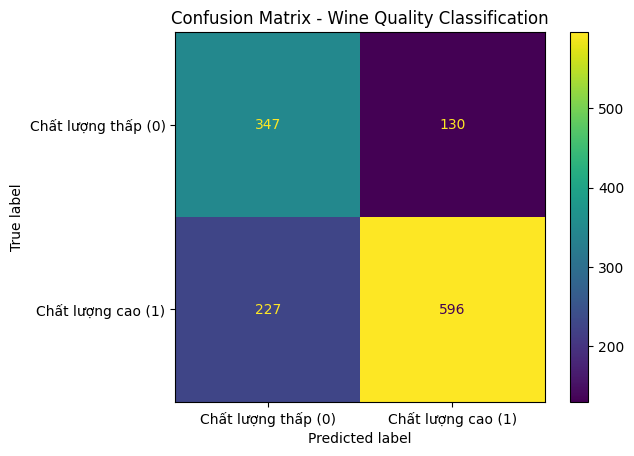

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Xử lý biến phân loại (nếu có cột 'type' đại diện cho rượu đỏ/trắng)
if 'type' in wine_df.columns:
    wine_processed = pd.get_dummies(wine_df, columns=['type'], drop_first=True)
else:
    wine_processed = wine_df.copy()

# Loại bỏ cột 'quality' gốc và 'target' để tạo ma trận đặc trưng X
X_wine = wine_processed.drop(columns=['quality', 'target'], errors='ignore')
y_wine = wine_processed['target']

# Chia tập Train/Test theo tỉ lệ 80:20
X_train_w, X_test_w, y_train_w, y_test_w = train_test_split(
    X_wine, y_wine, test_size=0.20, random_state=42, stratify=y_wine
)

# Xây dựng Pipeline chuẩn hóa + SMOTE + Logistic Regression
wine_pipeline = ImbPipeline([
    ("scaler", StandardScaler()),
    ("sampler", SMOTE(random_state=42)),
    ("model", LogisticRegression(max_iter=5000, random_state=42))
])

# Huấn luyện mô hình
wine_pipeline.fit(X_train_w, y_train_w)

# Dự đoán và đánh giá
y_pred_w = wine_pipeline.predict(X_test_w)

print("Báo cáo hiệu năng trên tập Test:")
print(classification_report(y_test_w, y_pred_w, digits=4))

# Hiển thị Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test_w, y_pred_w, display_labels=["Chất lượng thấp (0)", "Chất lượng cao (1)"]
)
plt.title("Confusion Matrix - Wine Quality Classification")
plt.show()